# Tutorial 6: Population Networks, Graph Measures, and Scale

This tutorial covers the building blocks added in braintools 0.4:

- **fixed-degree connectivity**: `FixedInDegree`, `FixedOutDegree`, and `FixedTotalNum`;
- **population networks**: `Population`, `Projection`, and `Network`, which assemble block connectivity in one global index space;
- **export to `brainevent`** sparse formats (`CSR`, `CSC`, `FixedNumPerPre`, `FixedNumPerPost`) and an event-driven spiking simulation that uses them;
- **structural graph measures** from `braintools.analysis.graph`;
- **scale**: building and exporting networks of 1e5 neurons on a laptop.

In [1]:
import time

import brainevent
import brainstate
import brainunit as u
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools.conn as conn
from braintools.analysis import graph

## 1. Fixed-degree connectivity

`FixedProb(p)` connects every pair independently, so the number of inputs a neuron receives is binomially distributed. The fixed-degree generators instead fix the count exactly:

- `FixedInDegree(k)`: every postsynaptic neuron receives exactly `k` inputs;
- `FixedOutDegree(k)`: every presynaptic neuron makes exactly `k` outputs;
- `FixedTotalNum(n)`: exactly `n` connections in total, placed uniformly at random.

`k` (or `n`) may also be a fraction in `(0, 1]` of the population size. By default the partners of a neuron are distinct (`with_replacement=False`).

In [2]:
n = 1000
results = {
    'FixedProb(0.05)': conn.FixedProb(0.05, seed=0)(pre_size=n, post_size=n),
    'FixedInDegree(50)': conn.FixedInDegree(50, seed=0)(pre_size=n, post_size=n),
    'FixedOutDegree(50)': conn.FixedOutDegree(50, seed=0)(pre_size=n, post_size=n),
    'FixedTotalNum(50000)': conn.FixedTotalNum(50_000, seed=0)(pre_size=n, post_size=n),
}
for name, res in results.items():
    din = graph.degree_distribution(res, direction='in').degrees
    dout = graph.degree_distribution(res, direction='out').degrees
    print(f'{name:22s} edges={res.n_connections:6d}  '
          f'in-degree {din.min():3d}..{din.max():3d}  out-degree {dout.min():3d}..{dout.max():3d}')

FixedProb(0.05)        edges= 49956  in-degree  31.. 70  out-degree  29.. 79
FixedInDegree(50)      edges= 50000  in-degree  50.. 50  out-degree  28.. 75
FixedOutDegree(50)     edges= 50000  in-degree  28.. 75  out-degree  50.. 50
FixedTotalNum(50000)   edges= 50000  in-degree  27.. 71  out-degree  31.. 76


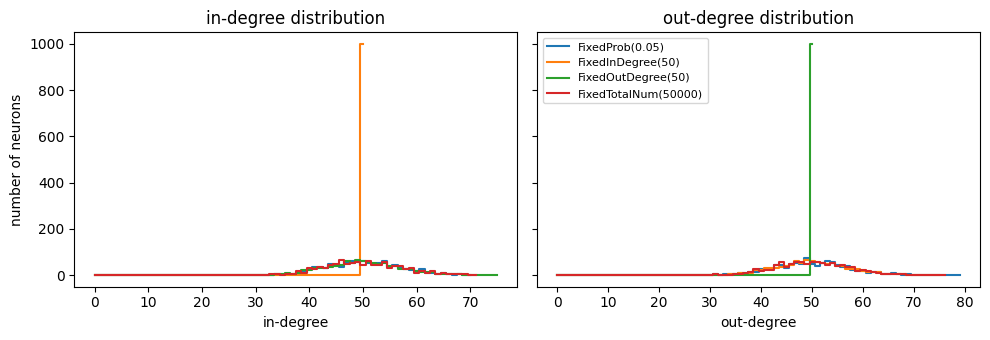

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, direction in zip(axes, ['in', 'out']):
    for name, res in results.items():
        dd = graph.degree_distribution(res, direction=direction)
        ax.step(dd.values, dd.counts, where='mid', label=name)
    ax.set_xlabel(f'{direction}-degree')
    ax.set_title(f'{direction}-degree distribution')
axes[0].set_ylabel('number of neurons')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The fixed side of each generator is a single spike in the histogram; the other side is binomial, like `FixedProb`.

## 2. Population networks

A `Population` is a named group of neurons, optionally with positions. A `Projection` binds a connectivity generator to a presynaptic and a postsynaptic population. A `Network` numbers all neurons globally (populations concatenated in order) and assembles the projections into one block matrix.

Below is a sparse E/I network in the style of Brunel (2000): 4000 excitatory and 1000 inhibitory neurons, and every neuron receives 400 excitatory and 100 inhibitory inputs. Weights are membrane-potential jumps in mV; inhibition is 5 times stronger than excitation.

In [4]:
J, g = 0.1, 5.0  # mV
E = conn.Population(4000, name='E')
I = conn.Population(1000, name='I')
net = conn.Network(
    [E, I],
    [
        conn.Projection(E, E, conn.FixedInDegree(400, weight=J * u.mV, seed=1)),
        conn.Projection(E, I, conn.FixedInDegree(400, weight=J * u.mV, seed=2)),
        conn.Projection(I, E, conn.FixedInDegree(100, weight=-g * J * u.mV, seed=3)),
        conn.Projection(I, I, conn.FixedInDegree(100, weight=-g * J * u.mV, seed=4)),
    ],
)
print(net)
print('offsets:', net.offsets, ' neurons:', net.n_neurons)
for name, res in net.build().items():
    print(f'{name}: shape={res.shape}, edges={res.n_connections}')

Network(populations=['E', 'I'], projections=['E->E', 'E->I', 'I->E', 'I->I'], n_neurons=5000)
offsets: {'E': 0, 'I': 4000}  neurons: 5000


E->E: shape=(4000, 4000), edges=1600000
E->I: shape=(4000, 1000), edges=400000
I->E: shape=(1000, 4000), edges=400000
I->I: shape=(1000, 1000), edges=100000


`Network.to_csr()` returns one `brainevent.CSR` of shape `(n_neurons, n_neurons)`: rows are presynaptic and columns postsynaptic neurons in global indices. Weight units are converted to the unit of the first projection.

CSR (5000, 5000) nonzeros: 2500000


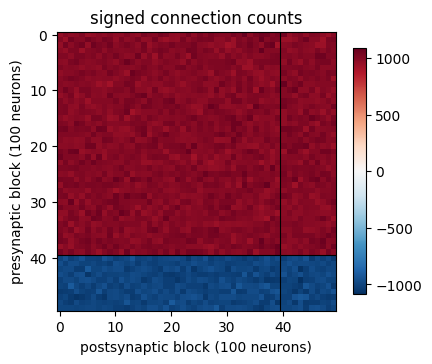

In [5]:
W = net.to_csr()
print(type(W).__name__, W.shape, 'nonzeros:', W.nse)

# Block structure: signed connection counts between groups of 100 neurons
indptr, indices = np.asarray(W.indptr), np.asarray(W.indices)
pre = np.repeat(np.arange(W.shape[0]), np.diff(indptr))
sign = np.sign(np.asarray(u.get_mantissa(W.data)))
blocks = np.zeros((50, 50))
np.add.at(blocks, (pre // 100, indices // 100), sign)
vmax = np.abs(blocks).max()
plt.figure(figsize=(4.5, 4))
plt.imshow(blocks, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
plt.axhline(39.5, color='k', lw=0.8)
plt.axvline(39.5, color='k', lw=0.8)
plt.xlabel('postsynaptic block (100 neurons)')
plt.ylabel('presynaptic block (100 neurons)')
plt.title('signed connection counts')
plt.colorbar(shrink=0.8)
plt.show()

## 3. Export to `brainevent` and simulate

`ConnectionResult` exports a single projection to every `brainevent` format:

| Method | Format | Requirement |
|---|---|---|
| `weight2csr()` | `CSR` (rows = pre) | none |
| `to_csc()` | `CSC` (columns = post) | none |
| `to_fixed_num_per_pre()` | `FixedNumPerPre` | every pre neuron has the same out-degree |
| `to_fixed_num_per_post()` | `FixedNumPerPost` | every post neuron has the same in-degree |
| `to_scipy_csr()` | `scipy.sparse.csr_array` | none (host-side, for analysis) |

A homogeneous weight stays a scalar, so the fixed-number formats store only the `(n, k)` index table.

In [6]:
res_ee = net.build()['E->E']
fn = res_ee.to_fixed_num_per_post()
print(type(fn).__name__, fn.shape, 'indices:', fn.indices.shape, 'weight:', fn.data)

FixedNumPerPost (4000, 4000) indices: (4000, 400) weight: 0.1 mV


The block CSR drives an event-driven network of leaky integrate-and-fire neurons. Each step multiplies the boolean spike vector by `W` (only the rows of neurons that spiked are touched), and `brainstate.transform.for_loop` compiles the whole simulation into one XLA program.

The neurons receive a constant suprathreshold drive plus white noise; recurrent inhibition dominates, which keeps the network in an asynchronous irregular state.

In [7]:
n_total = net.n_neurons
dt, tau, v_th, v_reset, t_ref = 0.1, 20.0, 20.0, 10.0, 2.0  # ms, ms, mV, mV, ms
mu, sigma = 24.0, 2.0  # mV

brainstate.random.seed(0)
V = brainstate.ShortTermState(brainstate.random.uniform(0.0, v_th, n_total))
spk = brainstate.ShortTermState(jnp.zeros(n_total, dtype=bool))
last = brainstate.ShortTermState(jnp.full(n_total, -1e7))


def step(i):
    t = i * dt
    syn = u.get_mantissa(brainevent.BinaryArray(spk.value) @ W)  # mV jumps from last step's spikes
    noise = sigma * jnp.sqrt(dt / tau) * brainstate.random.randn(n_total)
    v = V.value + dt / tau * (mu - V.value) + syn + noise
    v = jnp.where(t - last.value < t_ref, v_reset, v)
    fired = v >= v_th
    V.value = jnp.where(fired, v_reset, v)
    last.value = jnp.where(fired, t, last.value)
    spk.value = fired
    return fired


n_steps = 5000  # 500 ms
t0 = time.perf_counter()
spikes = np.asarray(brainstate.transform.for_loop(step, jnp.arange(n_steps)))
print(f'simulated {n_steps * dt:.0f} ms of {n_total} neurons in {time.perf_counter() - t0:.2f} s')
rate = spikes[1000:].mean() / (dt * 1e-3)
print(f'mean rate after 100 ms: {rate:.1f} Hz')

simulated 500 ms of 5000 neurons in 3.42 s
mean rate after 100 ms: 21.9 Hz


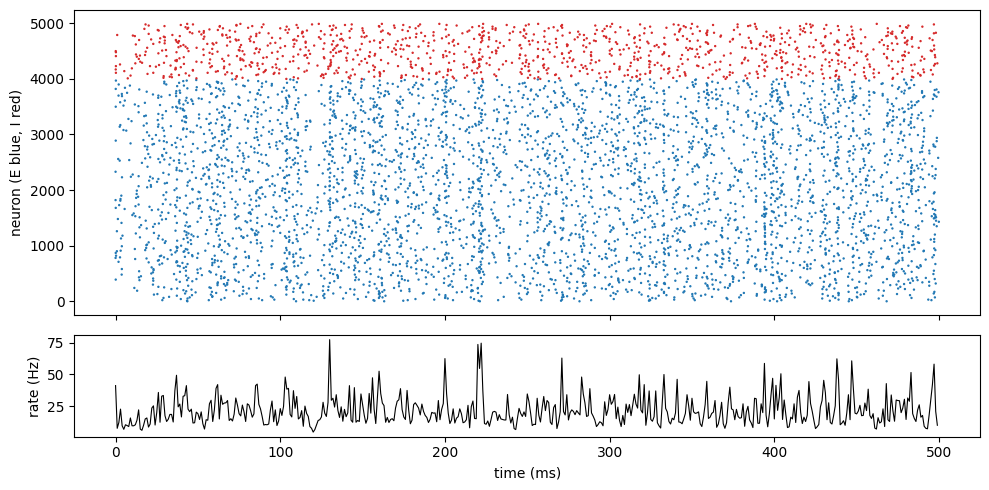

In [8]:
t_idx, n_idx = np.nonzero(spikes[:, ::10])  # every 10th neuron
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
colors = np.where(n_idx * 10 < 4000, 'tab:blue', 'tab:red')
ax1.scatter(t_idx * dt, n_idx * 10, s=0.5, c=colors)
ax1.set_ylabel('neuron (E blue, I red)')
pop_rate = spikes.reshape(-1, 10, n_total).mean(axis=(1, 2)) / (dt * 1e-3)
ax2.plot(np.arange(pop_rate.size) * dt * 10, pop_rate, 'k', lw=0.8)
ax2.set_xlabel('time (ms)')
ax2.set_ylabel('rate (Hz)')
plt.tight_layout()
plt.show()

## 4. Structural graph measures

`braintools.analysis.graph` measures the structure of a connectivity. Every function accepts a `ConnectionResult`, a SciPy sparse matrix, or a dense adjacency matrix, and works on sparse matrices. The results match `networkx`, including how self-connections are treated (counted by degrees and modularity, ignored by clustering and path length).

### Clustering, path length, and small-worldness

The Watts-Strogatz `SmallWorld` generator starts from a ring lattice and rewires each edge with probability `p`. Clustering stays high while the path length collapses for small `p`; the small-world index `sigma = (C / C_rand) / (L / L_rand)` compares both with Erdos-Renyi graphs of the same size.

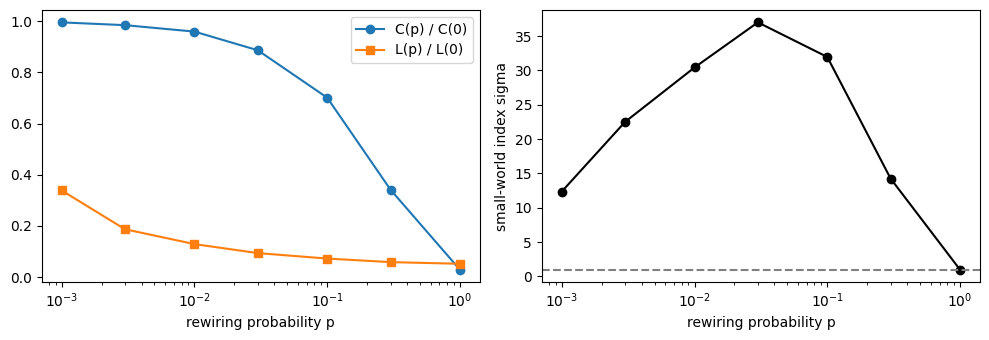

p=0.001  sigma= 12.34
p=0.003  sigma= 22.49
p=0.01   sigma= 30.42
p=0.03   sigma= 36.99
p=0.1    sigma= 31.95
p=0.3    sigma= 14.23
p=1.0    sigma=  0.96


In [9]:
n_sw = 1000
ps = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
C, L, sigma = [], [], []
for p in ps:
    res = conn.SmallWorld(k=10, p=p, seed=0)(pre_size=n_sw, post_size=n_sw)
    sw = graph.small_world_index(res, n_random=5, seed=0)
    C.append(sw.clustering)
    L.append(sw.path_length)
    sigma.append(sw.sigma)
lattice = conn.SmallWorld(k=10, p=0.0, seed=0)(pre_size=n_sw, post_size=n_sw)
C0 = graph.clustering_coefficient(lattice)
L0 = graph.characteristic_path_length(lattice).path_length

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.semilogx(ps, np.array(C) / C0, 'o-', label='C(p) / C(0)')
ax1.semilogx(ps, np.array(L) / L0, 's-', label='L(p) / L(0)')
ax1.set_xlabel('rewiring probability p')
ax1.legend()
ax2.semilogx(ps, sigma, 'o-k')
ax2.axhline(1.0, color='gray', ls='--')
ax2.set_xlabel('rewiring probability p')
ax2.set_ylabel('small-world index sigma')
plt.tight_layout()
plt.show()
for p, s in zip(ps, sigma):
    print(f'p={p:<6} sigma={s:6.2f}')

### Modularity

`modularity(conn, labels)` scores a partition of the neurons. For a `ModularRandom` network the planted modules score high, and a random relabelling scores about zero.

In [10]:
n_mod, n_modules = 800, 4
res_mod = conn.ModularRandom(n_modules, intra_prob=0.1, inter_prob=0.005, seed=0)(pre_size=n_mod, post_size=n_mod)
labels = np.repeat(np.arange(n_modules), n_mod // n_modules)
shuffled = np.random.default_rng(0).permutation(labels)
print(f'planted modules: Q = {graph.modularity(res_mod, labels):.3f}')
print(f'shuffled labels: Q = {graph.modularity(res_mod, shuffled):.3f}')

planted modules: Q = 0.615
shuffled labels: Q = -0.001


### Motifs and reciprocity

`motif_counts` returns the 16-class triad census (in `networkx.triadic_census` order), the dyad counts, and the reciprocity. Compared with a random graph of the same density, a small-world graph built from a symmetric lattice is strongly reciprocal and rich in closed triangles (triad class `'300'`).

In [11]:
rand = conn.FixedProb(10 / n_sw, seed=0)(pre_size=n_sw, post_size=n_sw)
sw = conn.SmallWorld(k=10, p=0.1, seed=0)(pre_size=n_sw, post_size=n_sw)
for name, res in [('FixedProb', rand), ('SmallWorld', sw)]:
    m = graph.motif_counts(res)
    print(f"{name:10s} reciprocity={m.reciprocity:.3f}  dyads={m.dyads}  triads '300'={m.triads['300']}")

FixedProb  reciprocity=0.007  dyads={'mutual': 37, 'asymmetric': 9919, 'null': 489544}  triads '300'=0
SmallWorld reciprocity=0.806  dyads={'mutual': 4032, 'asymmetric': 1936, 'null': 493532}  triads '300'=5280


### Spectral radius and stability

The spectral radius of the weight matrix governs the linear stability of rate dynamics and the echo-state property of reservoirs. For a random matrix with `K` zero-mean, unit-variance entries per column it approaches `sqrt(K)` (the circular law); rescaling the weights sets it to any target. The result keeps the weight unit.

In [12]:
n_res, k_res = 2000, 50
res_w = conn.FixedInDegree(k_res, seed=0)(pre_size=n_res, post_size=n_res)
csr = res_w.to_scipy_csr()
csr.data = np.random.default_rng(0).normal(0.0, 1.0, csr.nnz)
rho = graph.spectral_radius(csr)
print(f'spectral radius: {rho:.2f}  (circular law: sqrt(K) = {np.sqrt(k_res):.2f})')
csr.data = csr.data / rho
print(f'after rescaling: {graph.spectral_radius(csr):.3f}')

# non-negative weights: the radius equals the total input weight, K * J = 400 * 0.1 mV
print("E->E spectral radius:", graph.spectral_radius(net.build()["E->E"]))

spectral radius: 7.25  (circular law: sqrt(K) = 7.07)


after rescaling: 1.000
E->E spectral radius: 40. mV


## 5. Scale

The generators are vectorised NumPy and never build a dense `n_pre x n_post` array: all-pairs computations (distances, probabilities) run in row chunks of at most `2**22` pairs, so memory grows with the number of edges, not with the number of neuron pairs. The cell below builds two 1e5-neuron networks with 1e7 edges each and exports one to a `brainevent` fixed-number matrix.

In [13]:
N = 100_000

t0 = time.perf_counter()
res_fp = conn.FixedProb(1e-3, seed=0)(pre_size=N, post_size=N)
print(f'FixedProb(1e-3):    {res_fp.n_connections:>10,d} edges in {time.perf_counter() - t0:.1f} s')

t0 = time.perf_counter()
res_in = conn.FixedInDegree(100, seed=0)(pre_size=N, post_size=N)
print(f'FixedInDegree(100): {res_in.n_connections:>10,d} edges in {time.perf_counter() - t0:.1f} s')

t0 = time.perf_counter()
fn_big = res_in.to_fixed_num_per_post()
print(f'export to {type(fn_big).__name__}{fn_big.shape} in {time.perf_counter() - t0:.1f} s')

dd = graph.degree_distribution(res_fp, direction='in')
print(f'in-degree of FixedProb: mean {dd.degrees.mean():.1f}, sd {dd.degrees.std():.1f} '
      f'(binomial sd {np.sqrt(N * 1e-3 * (1 - 1e-3)):.1f})')
del res_fp, res_in, fn_big

FixedProb(1e-3):     9,999,978 edges in 2.1 s
FixedInDegree(100): 10,000,000 edges in 0.2 s


export to FixedNumPerPost(100000, 100000) in 0.1 s


in-degree of FixedProb: mean 100.0, sd 10.0 (binomial sd 10.0)


`benchmarks/conn_build.py` in the repository measures build time and peak memory, each case in its own process (`python benchmarks/conn_build.py`, or `--quick` for N = 1e4). Its cases are `FixedProb(0.001)`, `FixedInDegree(100)` with export, a distance-dependent `Gaussian` on a 2-D sheet, and an E/I `Network` exported to one block CSR.

## Summary

- `FixedInDegree`, `FixedOutDegree`, and `FixedTotalNum` fix the number of connections exactly.
- `Population`, `Projection`, and `Network` build block connectivity in a global index space; `Network.to_csr()` returns one `brainevent.CSR`.
- `ConnectionResult` exports to `CSR`, `CSC`, `FixedNumPerPre`, `FixedNumPerPost`, and SciPy.
- `braintools.analysis.graph` provides degree distributions, clustering, path length, modularity, motifs, spectral radius, and the small-world index.
- Generation is vectorised and memory-bounded, and scales to 1e5-neuron networks.